# Comparación de modelos de recuperación sobre FiQA (#12)

**Objetivo.** Comparar Jaccard binario, coseno TF-IDF, BM25 y MiniLM/FAISS con
las mismas 648 consultas test y sus qrels; analizar Porter y tipos observables
de consulta, y explicar una mejora y un retroceso del denso con evidencia real.
Las siete configuraciones proceden de #11. El denso se evalúa **una sola vez**,
sin variante Porter. Este análisis es descriptivo; no ajusta modelos con test.

Fuentes: [especificación](../docs/ESPECIFICACION.md),
[revisiones de FiQA](../docs/DATASET.md),
[contrato de evaluación](../reports/README.md),
[CSV](../reports/metrics_per_query.csv) y [JSON](../reports/metrics_summary.json).
Los resultados originales permanecen intactos. Reproducción completa en
[README](README.md). Los índices y el modelo deben construirse antes; este
notebook nunca vuelve a codificar el corpus.


In [1]:
import os
import sys
import warnings
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/ris").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HOME", str(ROOT / "data/hf_home"))
os.environ.setdefault("NLTK_DATA", str(ROOT / "data/nltk_data"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "data/matplotlib"))
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
(ROOT / "data/nltk_data").mkdir(parents=True, exist_ok=True)

# Aviso de barra interactiva opcional: no afecta al cálculo ni requiere otra dependencia.
warnings.filterwarnings("ignore", message="IProgress not found.*")

import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

from ris import comparison as cmp
from ris.data import load_queries
from ris.preprocessing import preprocess
from scripts.analyze_models import run, write_summary

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
FIGURES = ROOT / "artifacts/analysis/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def finish_figure(fig, name):
    fig.savefig(FIGURES / name, bbox_inches="tight", metadata={"Software": "RIS #12"})
    plt.show()
    plt.close(fig)

def config_label(model, stem):
    name = {"jaccard": "Jaccard", "tfidf": "TF-IDF", "bm25": "BM25", "dense": "Denso"}[model]
    return name + ({"false": " sin Porter", "true": " con Porter", "na": " (n/a)"}[stem])

METRIC_LABELS = {"precision": "P@10", "recall": "R@10", "ap_at_1000": "MAP@1000"}


## Método y validación de entradas

P@10 divide los aciertos por **10**; R@10 y AP@1000 dividen por **todos los
relevantes de la consulta** (`score > 0`). MAP@1000 es la media de AP@1000 sobre
las 648 consultas, incluidas las que obtienen cero. No juzgado no equivale a
juzgado no relevante. Los scores de modelos distintos no comparten escala.

`run` verifica esquema y tipos, split/cortes, variantes de `stem`, SHA-256 del
CSV, `counts.n_rows`, las mismas 648 cadenas `qid` sin duplicados por
configuración y todas las medias CSV/JSON (**atol=1e-12, rtol=0**). Contrasta
revisiones y hashes de corpus, consultas y qrels, recursos NLTK y conteos reales.
Carga los recuperadores existentes y recalcula los dos casos, con comprobación
independiente desde posiciones mediante fracciones exactas y `ris.evaluation`.
Si algo difiere, aborta; no sustituye silenciosamente los resultados de #11.

BM25 **con Porter** es el comparador fijado por convención. Los cambios de
Porter se calculan dentro de cada clásico (con − sin). No se elige un modelo
distinto por consulta. Las diferencias, mejoras, empeoramientos y empates usan
pares de la misma consulta; el umbral de empate descriptivo es ±1e-12.


In [2]:
summary = run(ROOT, ROOT / "artifacts")
queries = load_queries("test")
rows, evaluation = cmp.validate_reports(ROOT / "reports", set(queries))
frame = pd.DataFrame(rows)
frame["config"] = [config_label(m, s) for m, s in zip(frame.model, frame.stem)]
labels = [config_label(*c) for c in cmp.CONFIGURATIONS]
overall = pd.DataFrame(summary["overall"])
overall.index = labels
display(pd.DataFrame([summary["counts"]]).T.rename(columns={0: "Conteo comprobado"}))
print("CSV SHA-256:", summary["provenance"]["metrics_per_query_sha256"])
print("Igualdad de bytes de artefactos locales con #11:",
      summary["provenance"]["artifact_bytes_equal_to_original"])
print("Código de recuperación/evaluación:",
      summary["provenance"]["retrieval_evaluation_code_commit"])


Entradas verificadas: 4 536 filas, 648 qids × 7, hashes y medias (atol=1e-12).


Caso dense_improves: qid=2076, ΔAP=0.999371859


Caso dense_worsens: qid=1310, ΔAP=-0.991150442


,Conteo comprobado
n_queries,648
n_corpus_docs,57638
n_qrel_pairs,1706
n_relevant_pairs,1706
n_relevant_docs_distinct,1706
n_queries_without_relevant,0
n_relevant_docs_not_in_corpus,0
n_rows,4536


CSV SHA-256: c9ad4f7a06de53512f65ea4ef7b5a97b3d3666b680727c5c3433e74f0161a2ea
Igualdad de bytes de artefactos locales con #11: {'index_no_stem.json': True, 'index_stem.json': True, 'dense/metadata.json': True}
Código de recuperación/evaluación: d8793aacbf964155b54d42745d913f010c2cb8a2


## Resultados generales: 648 consultas en cada configuración

Cada celda es una media macro; las tres métricas son proporciones entre 0 y 1.
La tabla conserva las siete configuraciones y la figura muestra sus valores
sin convertir el denso en dos variantes de stemming.


,n,P@10,R@10,MAP@1000
Jaccard sin Porter,648,0.015432,0.063079,0.038520
Jaccard con Porter,648,0.015123,0.060502,0.038461
TF-IDF sin Porter,648,0.049074,0.217460,0.133028
TF-IDF con Porter,648,0.050463,0.219553,0.139718
BM25 sin Porter,648,0.063735,0.284832,0.180993
BM25 con Porter,648,0.069444,0.313021,0.206219
Denso (n/a),648,0.104475,0.441306,0.311586


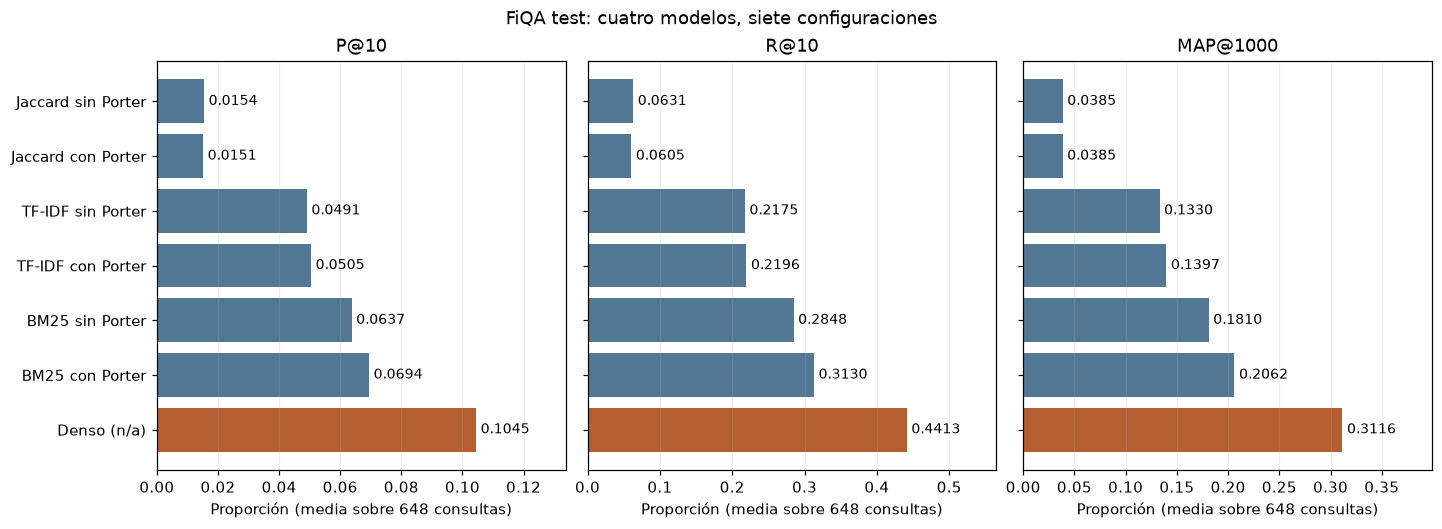

In [3]:
display(overall[["n", *cmp.METRICS]].rename(columns=METRIC_LABELS).style.format(
    {"P@10": "{:.6f}", "R@10": "{:.6f}", "MAP@1000": "{:.6f}"}))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.7), layout="constrained")
for ax, metric in zip(axes, cmp.METRICS):
    values = overall[metric].to_numpy()
    bars = ax.barh(labels, values, color=["#537895"] * 6 + ["#b55e32"])
    ax.invert_yaxis()
    ax.set(xlabel="Proporción (media sobre 648 consultas)", title=METRIC_LABELS[metric],
           xlim=(0, max(values) * 1.28))
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
    ax.grid(axis="x", alpha=.2)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("FiQA test: cuatro modelos, siete configuraciones")
finish_figure(fig, "12_general.png")


## Efecto de Porter dentro de cada modelo clásico

Δ absoluto = media con Porter − media sin Porter; Δ relativo = Δ absoluto /
media sin Porter (se expresa en %, y sería ausente si el denominador fuera 0).
Las columnas mejor/peor/igual cuentan diferencias **por consulta**, no pruebas
de significancia. Para AP@1000, la media del delta coincide con el cambio de MAP.


,Modelo,Métrica,n,Δ absoluto,Δ relativo (%),Mejor,Peor,Igual
0,jaccard,P@10,648,-0.000309,-2.00,19,22,607
1,jaccard,R@10,648,-0.002576,-4.08,19,22,607
2,jaccard,AP@1000 (media=ΔMAP),648,-0.000058,-0.15,198,293,157
3,tfidf,P@10,648,+0.001389,+2.83,59,57,532
4,tfidf,R@10,648,+0.002093,+0.96,59,57,532
5,tfidf,AP@1000 (media=ΔMAP),648,+0.006689,+5.03,278,283,87
6,bm25,P@10,648,+0.005710,+8.96,92,57,499
7,bm25,R@10,648,+0.028189,+9.90,92,57,499
8,bm25,AP@1000 (media=ΔMAP),648,+0.025227,+13.94,287,265,96


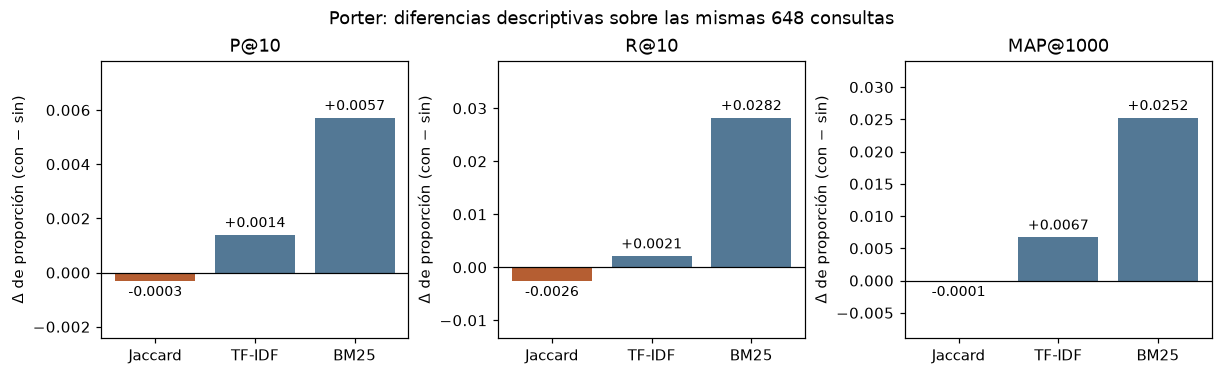

In [4]:
porter_rows = []
for comparison in summary["porter"]:
    for metric in cmp.METRICS:
        d = comparison[metric]
        porter_rows.append({"Modelo": comparison["target"][0],
            "Métrica": "AP@1000 (media=ΔMAP)" if metric == "ap_at_1000" else METRIC_LABELS[metric], "n": comparison["n"],
            "Δ absoluto": d["mean_delta"],
            "Δ relativo (%)": 100*d["relative_mean_delta"] if d["relative_mean_delta"] is not None else None,
            "Mejor": d["improved"], "Peor": d["worsened"], "Igual": d["tied"]})
display(pd.DataFrame(porter_rows).style.format({"Δ absoluto": "{:+.6f}", "Δ relativo (%)": "{:+.2f}"}))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
for ax, metric in zip(axes, cmp.METRICS):
    values = [d[metric]["mean_delta"] for d in summary["porter"]]
    bars = ax.bar(["Jaccard", "TF-IDF", "BM25"], values,
                  color=["#b55e32" if v < 0 else "#537895" for v in values])
    ax.axhline(0, color="black", lw=.8)
    ax.bar_label(bars, fmt="%+.4f", padding=3, fontsize=9)
    lo, hi = min(0, min(values)), max(0, max(values))
    margin = max(hi-lo, .001) * .35
    ax.set(ylim=(lo-margin, hi+margin), ylabel="Δ de proporción (con − sin)",
           title=METRIC_LABELS[metric])
fig.suptitle("Porter: diferencias descriptivas sobre las mismas 648 consultas")
finish_figure(fig, "12_porter.png")


## Diferencias pareadas frente a BM25 con Porter

Se muestran las seis alternativas frente al comparador fijo, para las tres
métricas. La tabla incluye los cuartiles **lineales** de las diferencias por
consulta y los extremos; ceros y empates se conservan. La figura amplía el
contraste denso−BM25. Son distribuciones descriptivas, sin inferencia causal
ni afirmación de significancia estadística.


,Alternativa,Métrica,n,Δ medio,Δ relativo (%),Mejor,Peor,Igual,min,p25,median,p75,max
0,Jaccard sin Porter,P@10,648,-0.0540,-77.7778,14,277,357,-0.5000,-0.1000,+0.0000,+0.0000,+0.1000
1,Jaccard sin Porter,R@10,648,-0.2499,-79.8484,14,277,357,-1.0000,-0.5000,+0.0000,+0.0000,+1.0000
2,Jaccard sin Porter,AP@1000 (media=ΔMAP),648,-0.1677,-81.3211,65,529,54,-1.0000,-0.2478,-0.0372,-0.0027,+0.8889
3,Jaccard con Porter,P@10,648,-0.0543,-78.2222,15,280,353,-0.5000,-0.1000,+0.0000,+0.0000,+0.1000
4,Jaccard con Porter,R@10,648,-0.2525,-80.6714,15,280,353,-1.0000,-0.5000,+0.0000,+0.0000,+1.0000
5,Jaccard con Porter,AP@1000 (media=ΔMAP),648,-0.1678,-81.3494,65,525,58,-1.0000,-0.2463,-0.0372,-0.0022,+0.9706
6,TF-IDF sin Porter,P@10,648,-0.0204,-29.3333,44,159,445,-0.4000,+0.0000,+0.0000,+0.0000,+0.2000
7,TF-IDF sin Porter,R@10,648,-0.0956,-30.5288,44,159,445,-1.0000,+0.0000,+0.0000,+0.0000,+1.0000
8,TF-IDF sin Porter,AP@1000 (media=ΔMAP),648,-0.0732,-35.4918,172,404,72,-0.9966,-0.0979,-0.0065,+0.0004,+0.9688
9,TF-IDF con Porter,P@10,648,-0.0190,-27.3333,26,137,485,-0.3000,+0.0000,+0.0000,+0.0000,+0.2000


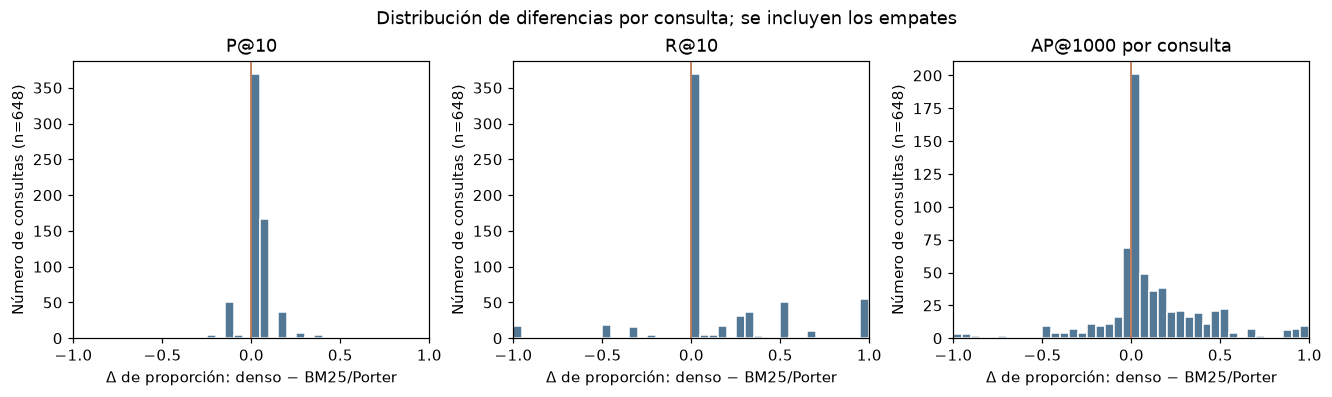

In [5]:
paired_rows = []
for comparison in summary["versus_bm25_porter"]:
    for metric in cmp.METRICS:
        d = comparison[metric]
        paired_rows.append({"Alternativa": config_label(*comparison["target"]),
            "Métrica": "AP@1000 (media=ΔMAP)" if metric == "ap_at_1000" else METRIC_LABELS[metric], "n": comparison["n"],
            "Δ medio": d["mean_delta"],
            "Δ relativo (%)": None if d["relative_mean_delta"] is None else 100*d["relative_mean_delta"],
            "Mejor": d["improved"], "Peor": d["worsened"], "Igual": d["tied"],
            **d["percentiles"]})
display(pd.DataFrame(paired_rows).style.format({key: "{:+.4f}" for key in (
    "Δ medio", "Δ relativo (%)", "min", "p25", "median", "p75", "max")}))
dense = frame[(frame.model == "dense") & (frame.stem == "na")].set_index("qid")
baseline = frame[(frame.model == "bm25") & (frame.stem == "true")].set_index("qid")
delta = dense[list(cmp.METRICS)] - baseline[list(cmp.METRICS)]
assert len(delta) == 648 and not delta.isna().any().any()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for ax, metric in zip(axes, cmp.METRICS):
    ax.hist(delta[metric], bins=np.linspace(-1, 1, 41), color="#537895", edgecolor="white")
    ax.axvline(0, color="#b55e32", lw=1)
    ax.set(title=METRIC_LABELS[metric] if metric != "ap_at_1000" else "AP@1000 por consulta",
           xlabel="Δ de proporción: denso − BM25/Porter", ylabel="Número de consultas (n=648)", xlim=(-1, 1))
fig.suptitle("Distribución de diferencias por consulta; se incluyen los empates")
finish_figure(fig, "12_diferencias.png")


## Tipos observables de consulta

Las reglas se fijan sobre el texto, antes de interpretar las métricas:

- Longitud tras `preprocess(stem=False)`: 0–3, 4–7 y ≥8 tokens.
- Números: presencia o ausencia de cualquier dígito en el texto original (`\d`).
- Mayúsculas: presencia o ausencia de una forma ASCII de ≥2 letras mayúsculas
  (`\b[A-Z]{2,}\b`). Es un **indicador de posible acrónimo**, no una etiqueta semántica;
  también detecta énfasis y puede omitir siglas con signos o dígitos.

Cada familia es una partición de las 648 consultas. Entre familias los grupos
se solapan: no deben sumarse como si fueran consultas distintas. No se asignan
temas manualmente ni se atribuye una diferencia a una característica aislada.
Los `qid` miembros quedan en el JSON para auditar la pertenencia.


**P@10 por grupo: medias macro y denominador n.**

,Jaccard sin Porter,Jaccard con Porter,TF-IDF sin Porter,TF-IDF con Porter,BM25 sin Porter,BM25 con Porter,Denso (n/a)
0–3 tokens (n=62),0.0097,0.0065,0.0355,0.0306,0.0484,0.0500,0.0839
4–7 tokens (n=402),0.0137,0.0132,0.0488,0.0515,0.0647,0.0714,0.1022
≥8 tokens (n=184),0.0212,0.0223,0.0543,0.0549,0.0668,0.0717,0.1163
Con dígitos (n=73),0.0151,0.0151,0.0548,0.0562,0.0575,0.0685,0.1041
Sin dígitos (n=575),0.0155,0.0151,0.0483,0.0497,0.0645,0.0696,0.1045
Con forma MAYÚSCULA (n=118),0.0229,0.0229,0.0602,0.0703,0.0712,0.0814,0.0983
Sin forma MAYÚSCULA (n=530),0.0138,0.0134,0.0466,0.0460,0.0621,0.0668,0.1058


**R@10 por grupo: medias macro y denominador n.**

,Jaccard sin Porter,Jaccard con Porter,TF-IDF sin Porter,TF-IDF con Porter,BM25 sin Porter,BM25 con Porter,Denso (n/a)
0–3 tokens (n=62),0.0346,0.0225,0.1402,0.1035,0.1980,0.1926,0.2773
4–7 tokens (n=402),0.0556,0.0534,0.2176,0.2237,0.2871,0.3227,0.4438
≥8 tokens (n=184),0.0890,0.0888,0.2432,0.2496,0.3091,0.3324,0.4910
Con dígitos (n=73),0.0354,0.0411,0.2258,0.2276,0.2280,0.2679,0.3743
Sin dígitos (n=575),0.0666,0.0630,0.2164,0.2185,0.2920,0.3187,0.4498
Con forma MAYÚSCULA (n=118),0.1142,0.1015,0.3242,0.3751,0.3944,0.4439,0.5541
Sin forma MAYÚSCULA (n=530),0.0517,0.0514,0.1937,0.1849,0.2604,0.2839,0.4162


**MAP@1000 por grupo: medias macro y denominador n.**

,Jaccard sin Porter,Jaccard con Porter,TF-IDF sin Porter,TF-IDF con Porter,BM25 sin Porter,BM25 con Porter,Denso (n/a)
0–3 tokens (n=62),0.0126,0.0087,0.0729,0.0564,0.1119,0.1058,0.1929
4–7 tokens (n=402),0.0351,0.0321,0.1335,0.1390,0.1836,0.2140,0.3086
≥8 tokens (n=184),0.0547,0.0624,0.1522,0.1694,0.1986,0.2230,0.3582
Con dígitos (n=73),0.0320,0.0347,0.1564,0.1535,0.1786,0.2011,0.2757
Sin dígitos (n=575),0.0394,0.0389,0.1301,0.1380,0.1813,0.2069,0.3161
Con forma MAYÚSCULA (n=118),0.0650,0.0674,0.2068,0.2296,0.2492,0.3089,0.4150
Sin forma MAYÚSCULA (n=530),0.0326,0.0320,0.1166,0.1197,0.1658,0.1834,0.2886


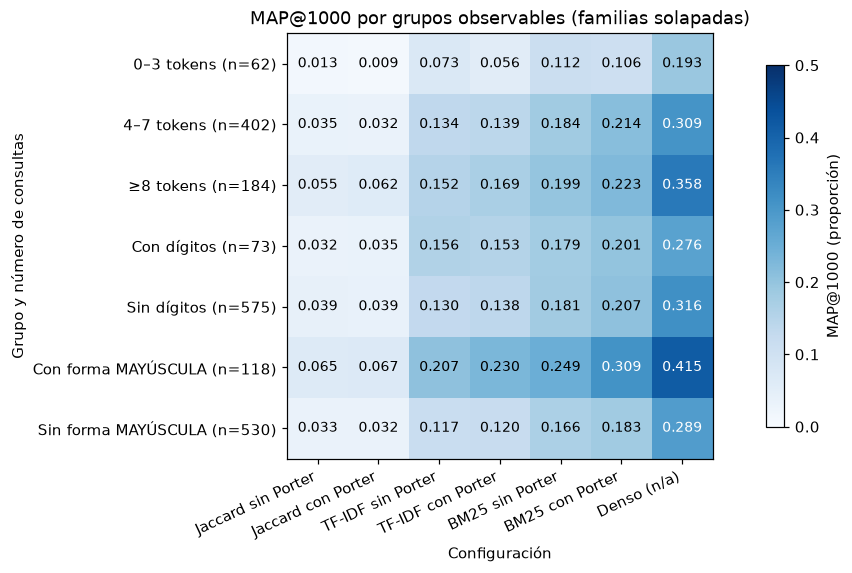

In [6]:
group_labels = {"length_0_3": "0–3 tokens", "length_4_7": "4–7 tokens",
    "length_8_plus": "≥8 tokens", "digits_yes": "Con dígitos", "digits_no": "Sin dígitos",
    "uppercase_yes": "Con forma MAYÚSCULA", "uppercase_no": "Sin forma MAYÚSCULA"}
for family in (("length_0_3", "length_4_7", "length_8_plus"),
               ("digits_yes", "digits_no"), ("uppercase_yes", "uppercase_no")):
    ids = [qid for key in family for qid in summary["groups"][key]["qids"]]
    assert len(ids) == len(set(ids)) == 648 and set(ids) == set(queries)
group_frames = {}
for metric in cmp.METRICS:
    group_frames[metric] = pd.DataFrame({
        f"{group_labels[key]} (n={summary['groups'][key]['n']})":
            [row[metric] for row in summary["groups"][key]["means"]]
        for key in group_labels}, index=labels).T
    display(Markdown(f"**{METRIC_LABELS[metric]} por grupo: medias macro y denominador n.**"))
    display(group_frames[metric].style.format("{:.4f}"))
heat = group_frames["ap_at_1000"]
fig, ax = plt.subplots(figsize=(11, 5.1), layout="constrained")
im = ax.imshow(heat.to_numpy(), cmap="Blues", vmin=0, vmax=.5)
ax.set_xticks(range(7), labels, rotation=25, ha="right")
ax.set_yticks(range(7), heat.index)
for y in range(7):
    for x in range(7):
        value = heat.iloc[y, x]
        ax.text(x, y, f"{value:.3f}", ha="center", va="center",
                color="white" if value > .27 else "black", fontsize=9)
ax.set(title="MAP@1000 por grupos observables (familias solapadas)",
       xlabel="Configuración", ylabel="Grupo y número de consultas")
fig.colorbar(im, ax=ax, label="MAP@1000 (proporción)", shrink=.85)
finish_figure(fig, "12_grupos.png")


### Lectura de los grupos

El denso obtiene la mayor MAP@1000 media en los siete grupos definidos; BM25
supera a TF-IDF y Jaccard en todos ellos, con ambas configuraciones de Porter.
Esto no significa que gane en cada consulta. Las consultas de ≥8 tokens muestran
MAP mayor que las de 0–3 en los cuatro modelos, pero longitud y dificultad no se
aislaron. Con dígitos la MAP del denso es 0,2757 frente a 0,3161 sin dígitos;
con formas mayúsculas, 0,4150 frente a 0,2886 sin ellas. Estos son promedios
de conjuntos diferentes y solapados, no efectos causales de números o siglas.
Porter reduce MAP de TF-IDF en el grupo corto (0,0624 → 0,0565), aunque su
media global suba. Las reglas no identifican todas las intenciones financieras.


## Dos casos ilustrativos seleccionados sin intervención manual

Métrica de selección: **AP@1000 denso − AP@1000 BM25 con Porter**.
Se eligen máximo positivo y mínimo negativo entre todas las 648 consultas;
empate exacto por `qid` ascendente como cadena. Los extremos no son ejemplos
representativos ni estiman la frecuencia de las mejoras. Si no existiera alguno
de los signos, se comunicaría su ausencia.

Se recupera top-1000 real con los recuperadores existentes. Las tablas muestran
top-10 y **todos** los relevantes, incluso fuera de top-10. Los scores se leen
solo dentro de su modelo. Los fragmentos son los primeros 600 caracteres exactos
del texto (sin normalización; offsets registrados). Se conserva la distinción
entre no juzgado y juzgado no relevante; estos qrels test solo tienen positivos.


In [7]:
for kind, case in summary["cases"].items():
    if case is None:
        display(Markdown(f"**{kind}:** no se encontraron consultas con el signo exigido."))
        continue
    display(Markdown(f"### {kind}: qid `{case['qid']}`\n\n{case['query']}\n\n"
        f"ΔAP@1000 = **{case['delta_ap_at_1000']:+.9f}**; "
        f"relevantes qrels = `{case['relevant_doc_ids']}` (n={case['n_relevant']})."))
    display(Markdown(f"Tokens de BM25/Porter: `{preprocess(case['query'], stem=True)}`. "
                     "El denso recibe el texto original de la consulta."))
    metric_table = pd.DataFrame({key: item["metrics"] for key, item in case["rankings"].items()}).T
    display(metric_table.rename(columns={**METRIC_LABELS, "ap_at_1000": "AP@1000"}).style.format("{:.9f}"))
    for label, item in case["rankings"].items():
        display(Markdown(f"**{label}**, {item['n_retrieved']} resultados recuperados; top-10 y relevantes:"))
        docs = item["documents"]
        display(pd.DataFrame([{ "doc_id": d["doc_id"], "Posición": str(d["rank"]) if d["rank"] else d["rank_status"],
            "Score del modelo": d["score"], "Juicio qrel": d["judgment"],
            "Score qrel": d["qrel_score"]} for d in docs]).style.format(
                {"Score del modelo": "{:.9f}"}, na_rep="—"))
        for doc in docs:
            if (doc["rank"] is not None and doc["rank"] <= 3) or doc["judgment"] == "relevante":
                display(HTML(f"<p><b>{html.escape(doc['doc_id'])}</b> · "
                    f"{html.escape(doc['judgment'])} · caracteres [0:{doc['snippet_end']}] "
                    f"de {doc['text_length']}</p><pre style='white-space:pre-wrap'>"
                    f"{html.escape(doc['snippet'])}</pre>"))


### dense_improves: qid `2076`

Can vet / veterinary bills be considered deductions (tax-deductible) for Income Tax purposes [Canada]?

ΔAP@1000 = **+0.999371859**; relevantes qrels = `['184646', '278824']` (n=2).

Tokens de BM25/Porter: `['vet', 'veterinari', 'bill', 'consid', 'deduct', 'tax', 'deduct', 'incom', 'tax', 'purpos', 'canada']`. El denso recibe el texto original de la consulta.

,P@10,R@10,AP@1000
bm25_true,0.000000000,0.000000000,0.000628141
dense_na,0.200000000,1.000000000,1.000000000


**bm25_true**, 1000 resultados recuperados; top-10 y relevantes:

,doc_id,Posición,Score del modelo,Juicio qrel,Score qrel
0,541809,1,24.779935383,no juzgado,—
1,212783,2,21.648901004,no juzgado,—
2,328073,3,21.544098593,no juzgado,—
3,235266,4,21.107115476,no juzgado,—
4,518624,5,20.839037069,no juzgado,—
5,228445,6,20.673983557,no juzgado,—
6,527776,7,20.051020702,no juzgado,—
7,41922,8,19.056460236,no juzgado,—
8,550345,9,18.831416153,no juzgado,—
9,87998,10,18.675126771,no juzgado,—


**dense_na**, 1000 resultados recuperados; top-10 y relevantes:

... (4 outputs left out)

**bm25_true**, 1000 resultados recuperados; top-10 y relevantes:

,doc_id,Posición,Score del modelo,Juicio qrel,Score qrel
0,535651,1,19.313164903,relevante,1.000000
1,143728,2,18.567990093,no juzgado,—
2,155624,3,18.470684421,no juzgado,—
3,101103,4,17.781195266,no juzgado,—
4,310056,5,16.652608342,no juzgado,—
5,84630,6,15.939440446,no juzgado,—
6,165710,7,15.616704223,no juzgado,—
7,354883,8,15.552042618,no juzgado,—
8,427604,9,14.873149279,no juzgado,—
9,15452,10,14.553591475,no juzgado,—


**dense_na**, 1000 resultados recuperados; top-10 y relevantes:

,doc_id,Posición,Score del modelo,Juicio qrel,Score qrel
0,101103,1,0.712774813,no juzgado,—
1,565972,2,0.649820566,no juzgado,—
2,235624,3,0.645238757,no juzgado,—
3,366448,4,0.636764169,no juzgado,—
4,277500,5,0.627447248,no juzgado,—
5,354883,6,0.615559697,no juzgado,—
6,95869,7,0.614386082,no juzgado,—
7,139978,8,0.613176107,no juzgado,—
8,403848,9,0.597099900,no juzgado,—
9,223338,10,0.596408367,no juzgado,—


### Qué explica la evidencia y qué queda como hipótesis

**2076.** Los dos relevantes, `278824` (los animales de servicio pueden deducirse,
las mascotas no) y `184646` (gastos médicos ante la Canada Revenue Agency), quedan
primero y segundo en el denso. BM25/Porter pone primero `541809`, sobre gastos
deducibles de una empresa, sin juicio para esta consulta; deja `184646` en la
posición 796 y no recupera `278824` en top-1000, así que AP = (1/796)/2 = 0,000628.
Ambos relevantes hablan de mascotas y perros sin repetir `vet` ni `veterinary`:
se observa falta de coincidencia léxica, sin afirmar que el encoder “comprenda”
el término ni que sea la única causa.

**1074 (máximo antes de corregir #3).** Con el preprocesamiento anterior, BM25/Porter
no recuperaba el relevante `443960` de *How common is “pass-through” health
insurance?* porque `pass-through` se descartaba entero. Tras la corrección lo
recupera en la posición 756 (AP=0,001323). El preprocesamiento fue el único cambio,
así que el resultado es compatible con la hipótesis de la pérdida de `pass-through`,
pero no aísla ese término de los demás trozos nuevos; tampoco basta para acercarse
al denso, que lo pone primero.

**1310.** `535651` contiene explícitamente el uso de bitcoins como garantía de un
préstamo y sus riesgos; BM25/Porter lo sitúa primero y el denso en la posición
113. Por tanto, P@10/R@10 pasan de 0,1/1 a 0/0 y AP de 1 a 1/113 = 0,00884956.
El primer resultado denso, `101103`, define la hipoteca como deuda garantizada por una propiedad; el segundo, `565972`, habla de hipotecas para comprar y arrendar. Ninguno tiene juicio para esta consulta. Se observa prioridad de contexto hipotecario general frente al relevante sobre bitcoins como garantía.
La caída es respecto a los qrels: documentos no juzgados podrían ser útiles.
No se atribuye el fallo a truncamiento ni se considera irrelevante todo el top
denso por carecer de juicio. Ningún score se compara entre modelos.


## Conclusiones descriptivas y límites

- En estas 648 consultas, el denso alcanza P@10=0,104475, R@10=0,441306 y
  MAP@1000=0,311586; BM25/Porter alcanza 0,069444, 0,313021 y 0,206219.
  El cambio de MAP es +0,105367 (+51,09% relativo). AP mejora en **443** consultas,
  empeora en **156** y empata en **49**. En P@10 y R@10: 219/60/369.
- Porter cambia MAP en Jaccard −0,000058 (−0,15%), TF-IDF +0,006689 (+5,03%) y
  BM25 +0,025227 (+13,94%). Una mejora macro puede convivir con muchas consultas
  perjudicadas; no es una recomendación universal de stemming.
- Los grupos son operativos, de tamaños distintos y solapados entre familias.
  No son una clasificación temática ni aíslan dificultad, longitud o intención.
  Las diferencias no se presentan como estadísticamente significativas.
- Los qrels pueden ser incompletos. La selección por extremos exagera contrastes
  a propósito y se separa de los promedios de todas las consultas.
- #11 comprueba los índices clásicos con una muestra determinista de 500
  documentos: eso no garantiza correspondencia total. En esta reproducción los
  dos hashes clásicos coinciden con #11. Los hashes NLTK describen recursos de la
  evaluación, no prueban por sí solos cómo se construyeron los índices originales.
- Desde el 16 de noviembre la tokenización clásica parte guiones, puntos y barras
  en trozos (`1.000` → `1`, `000`) y descarta `n't`. Frente al pipeline anterior,
  que descartaba esos tokens enteros, MAP@1000 sube en las seis configuraciones
  clásicas (BM25/Porter 0,198736 → 0,206219) y el denso no cambia. MiniLM usa texto original con un máximo de 256
  tokens, incluidos especiales; no se infiere que truncamiento explique un caso.
- En esta reconstrucción, embeddings y FAISS tienen hashes distintos de #11,
  con la misma revisión de MiniLM y versiones fijadas. No se ha diagnosticado
  la causa de la diferencia de bytes. Los cuatro casos reproducen sus métricas,
  lo que no prueba identidad de toda la evaluación densa en otro equipo.
- Los embeddings se reconstruyen una vez si faltan. Los hashes, versiones,
  lote e hilos locales se registran: igualdad bit a bit del denso puede depender
  de máquina, hilos y librerías. Las métricas de los cuatro rankings de casos se
  exigen iguales a #11 con atol=1e-12; los agregados se leen del CSV original.
- No se comparan valores publicados de BEIR ni se afinan parámetros con test.
  Notebook ejecutado y revisión visual son verificaciones locales; el CI ejecuta
  Ruff y pytest. No hay comprobación del despliegue en esta issue.


In [8]:
# Contrastes de conclusiones y salida pequeña; los rankings completos quedan en artifacts/.
assert summary["cases"]["dense_improves"]["qid"] == "2076"
assert summary["cases"]["dense_worsens"]["qid"] == "1310"
dense_comparison = next(d for d in summary["versus_bm25_porter"] if d["target"] == ["dense", "na"])
assert [dense_comparison["ap_at_1000"][key] for key in ("improved", "worsened", "tied")] == [443, 156, 49]
for key, table in group_frames.items():
    assert np.allclose(table.to_numpy(), np.array([
        [r[key] for r in summary["groups"][g]["means"]] for g in group_labels]), atol=1e-12, rtol=0)
    assert all(table.iloc[:, 6] > table.iloc[:, :6].max(axis=1))
write_summary(summary, ROOT / "reports/comparison_summary.json")
print("Resumen guardado: reports/comparison_summary.json")
print("Tamaño (bytes):", (ROOT / "reports/comparison_summary.json").stat().st_size)
display(pd.DataFrame(summary["provenance"]["analysis_versions"].items(), columns=["Componente", "Versión local"]))


Resumen guardado: reports/comparison_summary.json
Tamaño (bytes): 107127


,Componente,Versión local
0,python,3.12.10
1,faiss-cpu,1.15.1
2,huggingface_hub,2.4.0
3,nltk,3.10.4
4,numpy,2.5.4
5,pyarrow,26.0.1
6,sentence-transformers,6.2.0
7,torch,2.15.0+cpu
8,retrieval-information-system,0.1.0
9,pandas,3.1.1
